# Both Pooling vs Ambulance Pooling

Overlapping mortality distributions.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/sobol_no_t2_fixed_pooling/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]


Loaded 98304 runs


In [2]:
p1 = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
p2 = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
assert (p1["scenario"].values == p2["scenario"].values).all()

delta = p1["death_rate_T1_BCAS"].values - p2["death_rate_T1_BCAS"].values
print(f"both: {len(p1)} runs, median mort = {p1['death_rate_T1_BCAS'].median():.3f}")
print(f"amb: {len(p2)} runs, median mort = {p2['death_rate_T1_BCAS'].median():.3f}")
print(f"Delta median: {np.median(delta):.4f}")
print(f"Delta > 0 (both worse): {(delta > 0.01).sum()} / {len(delta)} ({(delta > 0.01).mean():.1%})")
print(f"Delta < 0 (both better): {(delta < -0.01).sum()} / {len(delta)} ({(delta < -0.01).mean():.1%})")


both: 24576 runs, median mort = 0.000
amb: 24576 runs, median mort = 0.000
Delta median: 0.0000
Delta > 0 (both worse): 1541 / 24576 (6.3%)
Delta < 0 (both better): 6408 / 24576 (26.1%)


## Mortality Distributions


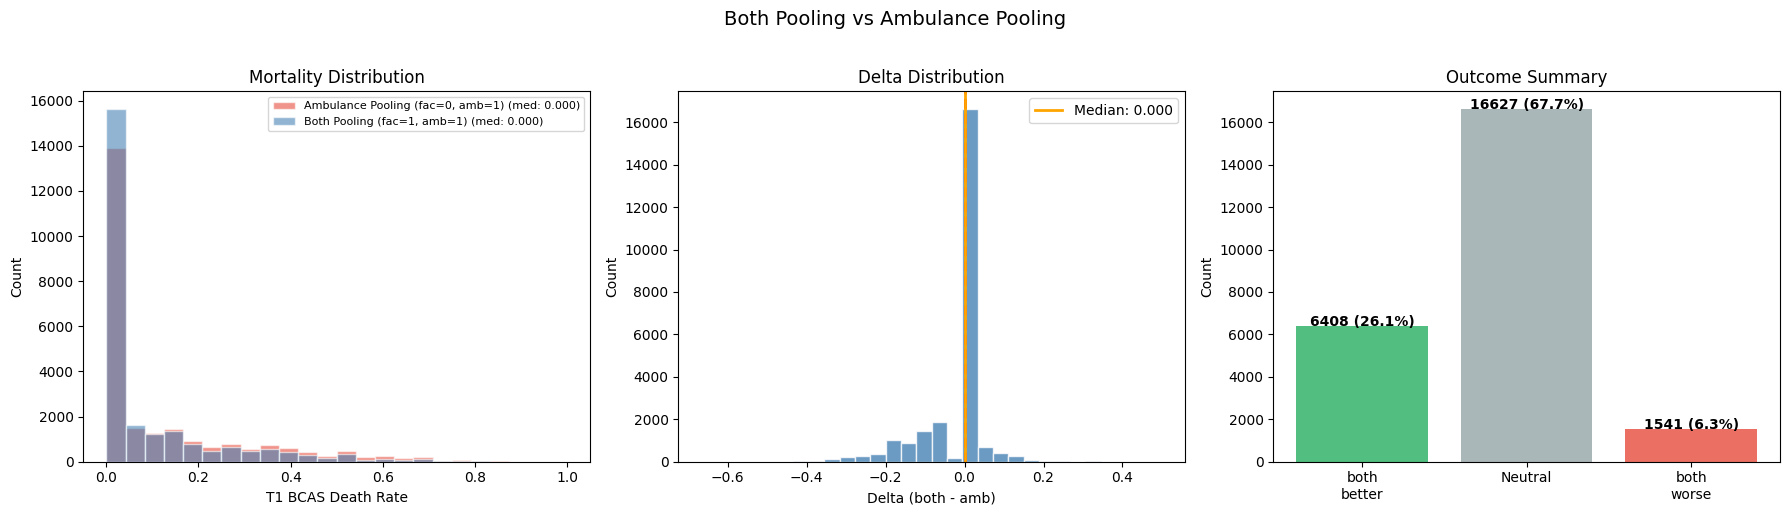

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bins = np.linspace(0, 1, 25)
axes[0].hist(p2["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white", label=f"Ambulance Pooling (fac=0, amb=1) (med: {p2['death_rate_T1_BCAS'].median():.3f})")
axes[0].hist(p1["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white", label=f"Both Pooling (fac=1, amb=1) (med: {p1['death_rate_T1_BCAS'].median():.3f})")
axes[0].set_xlabel("T1 BCAS Death Rate")
axes[0].set_ylabel("Count")
axes[0].set_title("Mortality Distribution")
axes[0].legend(fontsize=8)

axes[1].hist(delta, bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", linewidth=2, linestyle="--")
axes[1].axvline(np.median(delta), color="orange", linewidth=2, label=f"Median: {np.median(delta):.3f}")
axes[1].set_xlabel("Delta (both - amb)")
axes[1].set_ylabel("Count")
axes[1].set_title("Delta Distribution")
axes[1].legend()

n_better = (delta < -0.01).sum()
n_neutral = ((delta >= -0.01) & (delta <= 0.01)).sum()
n_worse = (delta > 0.01).sum()
bars = axes[2].bar(["both\nbetter", "Neutral", "both\nworse"],
                    [n_better, n_neutral, n_worse],
                    color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_better, n_neutral, n_worse]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f"{val} ({val/len(delta):.1%})", ha="center", fontweight="bold")
axes[2].set_ylabel("Count")
axes[2].set_title("Outcome Summary")

fig.suptitle("Both Pooling vs Ambulance Pooling", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## Stressed scenarios only (bcas >= 0.02)


Stressed: 20478 scenarios


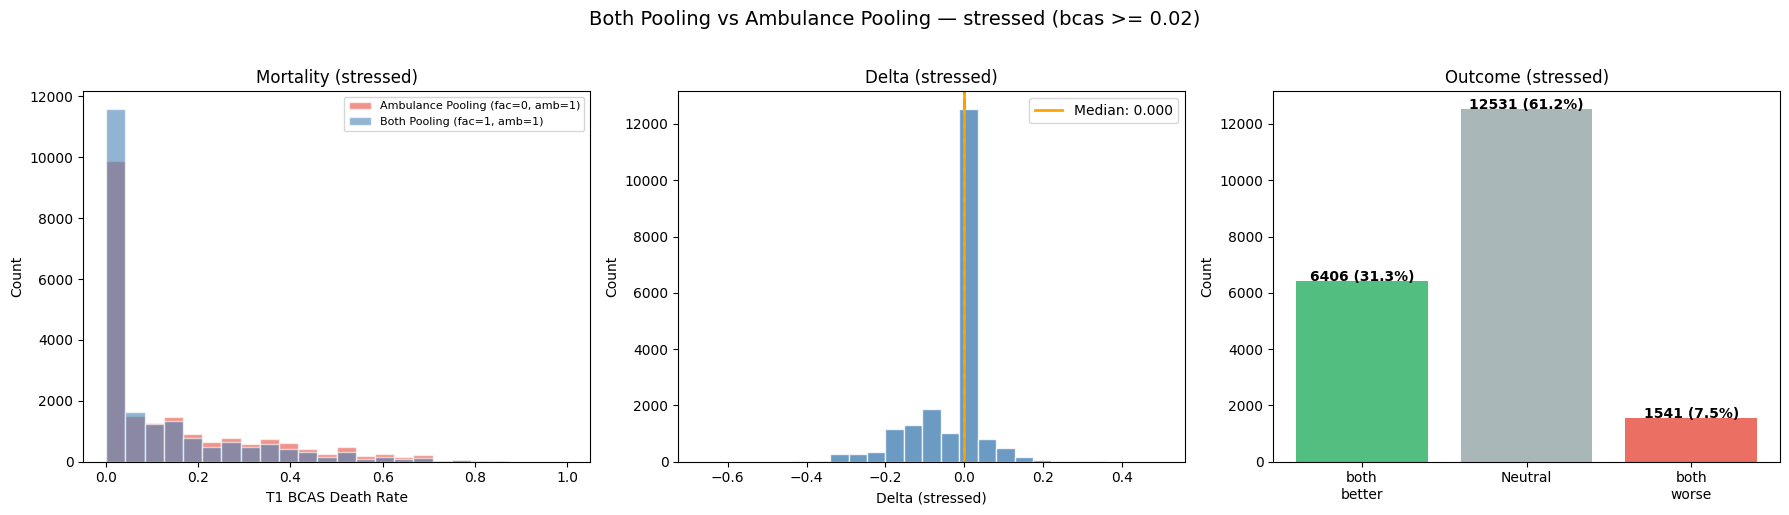

In [4]:
mask_s = p1["bcas_rate"] >= 0.02
p1s, p2s = p1[mask_s], p2[mask_s]
delta_s = p1s["death_rate_T1_BCAS"].values - p2s["death_rate_T1_BCAS"].values
print(f"Stressed: {len(p1s)} scenarios")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bins = np.linspace(0, 1, 25)
axes[0].hist(p2s["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white", label=f"Ambulance Pooling (fac=0, amb=1)")
axes[0].hist(p1s["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white", label=f"Both Pooling (fac=1, amb=1)")
axes[0].set_xlabel("T1 BCAS Death Rate")
axes[0].set_ylabel("Count")
axes[0].set_title("Mortality (stressed)")
axes[0].legend(fontsize=8)

axes[1].hist(delta_s, bins=25, color="steelblue", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", linewidth=2, linestyle="--")
axes[1].axvline(np.median(delta_s), color="orange", linewidth=2, label=f"Median: {np.median(delta_s):.3f}")
axes[1].set_xlabel("Delta (stressed)")
axes[1].set_ylabel("Count")
axes[1].set_title("Delta (stressed)")
axes[1].legend()

n_b = (delta_s < -0.01).sum()
n_n = ((delta_s >= -0.01) & (delta_s <= 0.01)).sum()
n_w = (delta_s > 0.01).sum()
bars = axes[2].bar(["both\nbetter", "Neutral", "both\nworse"],
                    [n_b, n_n, n_w], color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_b, n_n, n_w]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f"{val} ({val/len(delta_s):.1%})", ha="center", fontweight="bold")
axes[2].set_ylabel("Count")
axes[2].set_title("Outcome (stressed)")

fig.suptitle("Both Pooling vs Ambulance Pooling — stressed (bcas >= 0.02)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## PRIM — Where does adding facility pooling NOT benefit?

Find the box where delta ≈ 0 (adding fac to amb makes no difference).

Adding fac did NOT help: 18168 / 24576 (73.9%)



Box where adding facility pooling does NOT help:
coverage       0.128688
density        0.998292
id            37.000000
k           2338.000000
mass           0.095296
mean           0.998292
n           2342.000000
res_dim        4.000000
Name: 37, dtype: float64

                       box 37                                        
                          min        max      qp value       qp value
bcas_rate            0.010011   0.026538           NaN  1.580272e-107
ccp_r1_same_bn_min  10.000000  19.500000           NaN   1.472523e-01
waves_per_day        2.500000   6.000000  8.067239e-07            NaN
wave_duration_min   26.500000  60.000000  7.639248e-03            NaN



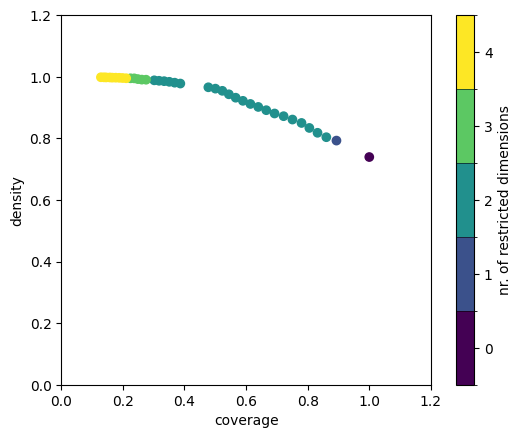

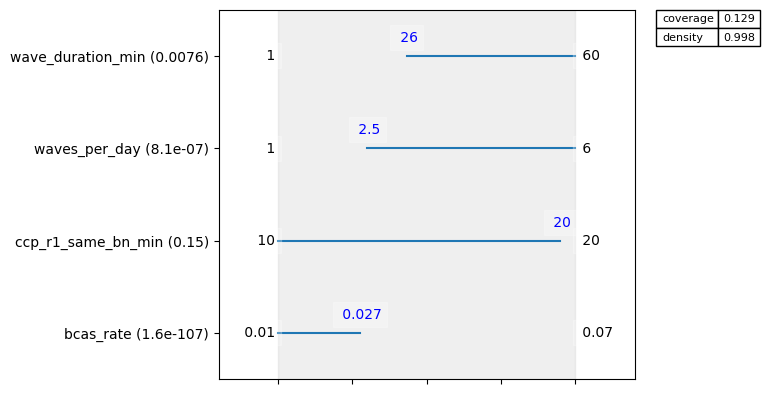

In [5]:
from ema_workbench.analysis import prim

x = p1[UNCERTAINTIES].astype(float)

# Where adding fac does NOT help (delta >= -0.01)
y_no_benefit = (delta >= -0.01)
print(f"Adding fac did NOT help: {y_no_benefit.sum()} / {len(y_no_benefit)} ({y_no_benefit.mean():.1%})")

if y_no_benefit.sum() >= 10 and y_no_benefit.sum() < len(y_no_benefit) * 0.95:
    p_nb = prim.Prim(x, y_no_benefit, threshold=0.5)
    box_nb = p_nb.find_box()
    box_nb.show_tradeoff()
    print()
    print("Box where adding facility pooling does NOT help:")
    box_nb.inspect(style="graph")
    box_nb.inspect()
elif y_no_benefit.sum() >= len(y_no_benefit) * 0.95:
    print("Adding fac fails to help in >95% of cases — no meaningful box to find.")
else:
    print("Too few cases for PRIM.")

## PRIM — Where DOES adding facility pooling benefit?

Adding fac helped: 6408 / 24576 (26.1%)



Box where adding facility pooling HELPS:


coverage       0.162921
density        0.808675
id            26.000000
k           1044.000000
mass           0.052531
mean           0.808675
n           1291.000000
res_dim        4.000000
Name: 26, dtype: float64

                       box 26                                        
                          min        max      qp value       qp value
waves_per_day        1.000000   1.500000           NaN  1.404173e-114
ccp_r1_same_bn_min  10.000000  19.500000           NaN   1.819986e-02
wave_duration_min    1.000000  42.500000           NaN   6.028221e-02
bcas_rate            0.040746   0.069995  7.188669e-73            NaN



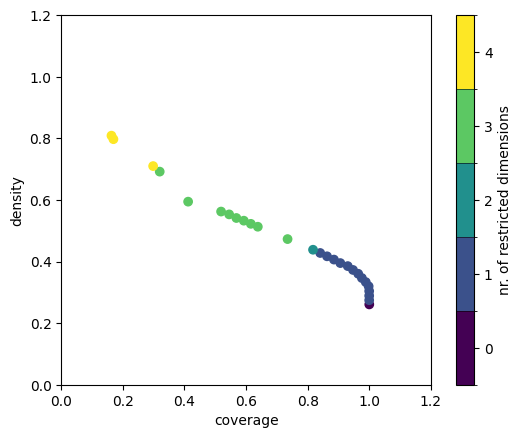

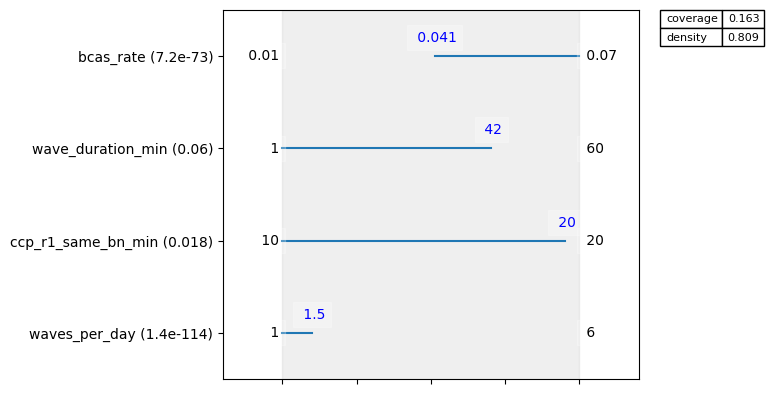

In [6]:
# Where adding fac DOES help (delta < -0.01)
y_benefit = (delta < -0.01)
print(f"Adding fac helped: {y_benefit.sum()} / {len(y_benefit)} ({y_benefit.mean():.1%})")

if y_benefit.sum() >= 10 and y_benefit.sum() < len(y_benefit) * 0.95:
    p_b = prim.Prim(x, y_benefit, threshold=0.5)
    box_b = p_b.find_box()
    box_b.show_tradeoff()
    print()
    print("Box where adding facility pooling HELPS:")
    box_b.inspect(style="graph")
    box_b.inspect()
elif y_benefit.sum() >= len(y_benefit) * 0.95:
    print("Adding fac helps in >95% of cases — no meaningful box to find.")
else:
    print("Too few cases for PRIM.")

## Diagnostic Matrix — Fac Doesn't Help vs Fac Helps

Rows: wait times and mortality at each phase. Columns: the two PRIM boxes.
Blues for wait times, Reds for mortality.

C:\Users\User\AppData\Local\Temp\claude\ipykernel_22648\2829531194.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


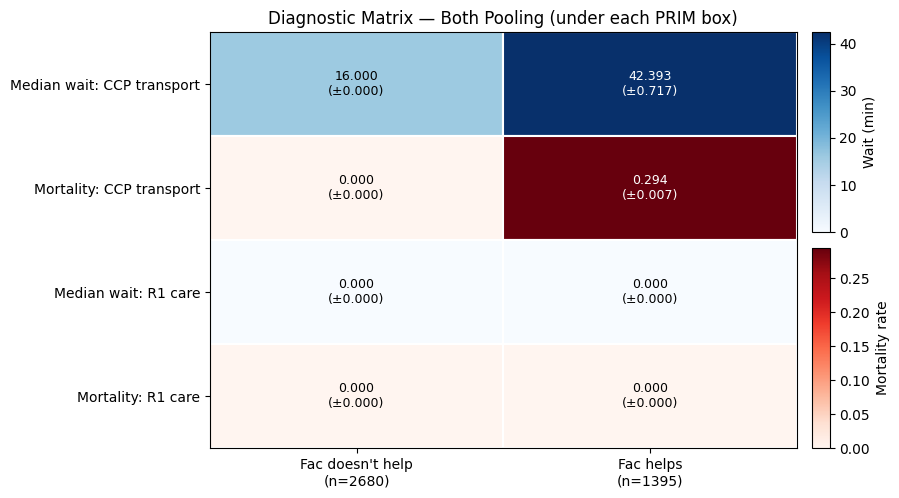

                            Fac doesn't help\n(n=2680)  Fac helps\n(n=1395)
Median wait: CCP transport                     16.0000              42.3932
Mortality: CCP transport                        0.0000               0.2941
Median wait: R1 care                            0.0000               0.0000
Mortality: R1 care                              0.0000               0.0000


In [7]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec

# Define the two boxes from PRIM results
box_no_help = (
    (p1["bcas_rate"] <= 0.027) &
    (p1["waves_per_day"] >= 2.5) &
    (p1["wave_duration_min"] >= 26.5)
)
box_helps = (
    (p1["bcas_rate"] >= 0.041) &
    (p1["waves_per_day"] <= 1.5) &
    (p1["wave_duration_min"] <= 42.5)
)

boxes = {
    f"Fac doesn't help\n(n={box_no_help.sum()})": box_no_help,
    f"Fac helps\n(n={box_helps.sum()})": box_helps,
}

# Outcomes to show (under "both" policy)
rows = [
    ("Median wait: CCP transport",  "median_wait_ccp_transport_T1"),
    ("Mortality: CCP transport",    "mortality_ccp_transport_T1"),
    ("Median wait: R1 care",        "median_wait_r1_care_T1"),
    ("Mortality: R1 care",          "mortality_r1_care_T1"),
]

# Build matrix
col_names = list(boxes.keys())
matrix = pd.DataFrame(index=[r[0] for r in rows], columns=col_names, dtype=float)
ci_mat = pd.DataFrame(index=[r[0] for r in rows], columns=col_names, dtype=float)

def median_ci(vals, n_boot=1000, alpha=0.05):
    if len(vals) < 2:
        return np.nan
    rng = np.random.default_rng(42)
    boots = np.array([np.median(rng.choice(vals, size=len(vals))) for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return (hi - lo) / 2

for col_name, mask in boxes.items():
    sub = p1[mask]
    for label, outcome in rows:
        vals = sub[outcome].dropna().values
        matrix.loc[label, col_name] = np.median(vals) if len(vals) > 0 else np.nan
        ci_mat.loc[label, col_name] = median_ci(vals) if len(vals) > 0 else np.nan

# Identify wait vs mortality rows
wait_idx = [i for i, (lab, _) in enumerate(rows) if lab.startswith("Median wait")]
mort_idx = [i for i, (lab, _) in enumerate(rows) if lab.startswith("Mortality")]

vals_f = matrix.values.astype(float)
wait_vals = vals_f[wait_idx, :].flatten()
mort_vals = vals_f[mort_idx, :].flatten()
norm_wait = Normalize(vmin=np.nanmin(wait_vals), vmax=max(np.nanmax(wait_vals), 0.01))
norm_mort = Normalize(vmin=np.nanmin(mort_vals), vmax=max(np.nanmax(mort_vals), 0.01))
cmap_wait = plt.cm.Blues
cmap_mort = plt.cm.Reds

n_rows, n_cols = vals_f.shape

fig = plt.figure(figsize=(8, n_rows * 0.85 + 2))
gs = gridspec.GridSpec(2, 2, width_ratios=[1, 0.03], height_ratios=[1, 1],
                       wspace=0.05, hspace=0.08)
ax = fig.add_subplot(gs[:, 0])
cax_w = fig.add_subplot(gs[0, 1])
cax_m = fig.add_subplot(gs[1, 1])

for i in range(n_rows):
    is_mort = i in mort_idx
    norm = norm_mort if is_mort else norm_wait
    cmap = cmap_mort if is_mort else cmap_wait
    for j in range(n_cols):
        v = vals_f[i, j]
        color = cmap(norm(v)) if not np.isnan(v) else (0.95, 0.95, 0.95, 1)
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor="white", lw=1.5))
        if not np.isnan(v):
            ci = ci_mat.iloc[i, j]
            txt = f"{v:.3f}\n(±{ci:.3f})" if not np.isnan(ci) else f"{v:.3f}"
            brightness = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2]
            ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                    color="white" if brightness < 0.55 else "black")

ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(n_rows - 0.5, -0.5)
ax.set_xticks(range(n_cols))
ax.set_xticklabels(col_names, fontsize=10)
ax.set_yticks(range(n_rows))
ax.set_yticklabels([r[0] for r in rows])
ax.set_title("Diagnostic Matrix — Both Pooling (under each PRIM box)")

fig.colorbar(ScalarMappable(norm=norm_wait, cmap=cmap_wait), cax=cax_w, label="Wait (min)")
fig.colorbar(ScalarMappable(norm=norm_mort, cmap=cmap_mort), cax=cax_m, label="Mortality rate")

plt.tight_layout()
plt.show()

print(matrix.to_string(float_format="%.4f"))